# Churn Prediction & Segmentation – E-commerce

<a href="https://colab.research.google.com/github/YOUR_USERNAME/YOUR_REPO/blob/main/ML_final_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Notebook chạy trực tiếp trên **Google Colab**: dữ liệu sẽ được tự động tải về thư mục `raws/` nếu chưa có. Chọn **Runtime → Run all** để chạy toàn bộ.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import missingno as msno

In [2]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (precision_score, recall_score, balanced_accuracy_score,
                             classification_report, ConfusionMatrixDisplay, silhouette_score)
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

In [3]:
import os

DATA_PATH = "raws/churn_prediction.xlsx"

# Trên Google Colab (hoặc khi chưa có file), tải dữ liệu từ Google Drive vào thư mục raws/
if not os.path.exists(DATA_PATH):
    import gdown  # có sẵn trên Colab; chạy local thì: pip install gdown
    os.makedirs("raws", exist_ok=True)
    gdown.download(id="1g7_8-ijuwZa0S_aPTbqAexfhRC0yY_bn", output=DATA_PATH, quiet=False)

In [4]:
df = pd.read_excel(DATA_PATH)
df.head(2)

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,52869,0,20.0,Mobile Phone,3,7.0,E wallet,Female,4.0,4,Fashion,5,Married,3,0,26.0,5.0,16.0,NaN,229.53
1,52942,0,13.0,Computer,1,9.0,Cash on Delivery,Female,4.0,4,Fashion,3,Single,2,0,26.0,11.0,NaN,9.0,234.38


###**1. Data Preprocessing:**


In [5]:
df.columns = df.columns.str.lower()
df.columns

Index(['customerid', 'churn', 'tenure', 'preferredlogindevice', 'citytier',
       'warehousetohome', 'preferredpaymentmode', 'gender', 'hourspendonapp',
       'numberofdeviceregistered', 'preferedordercat', 'satisfactionscore',
       'maritalstatus', 'numberofaddress', 'complain',
       'orderamounthikefromlastyear', 'couponused', 'ordercount',
       'daysincelastorder', 'cashbackamount'],
      dtype='str')

In [6]:
df.shape

(5630, 20)

In [7]:
churn_df = df.groupby('churn')['customerid'].count().reset_index()
churn_df['ratio'] = churn_df['customerid'] / sum(churn_df['customerid'])
churn_df

,churn,customerid,ratio
0,0,4682,0.831616
1,1,948,0.168384


#### **1.1 Missing values:**

<Axes: >

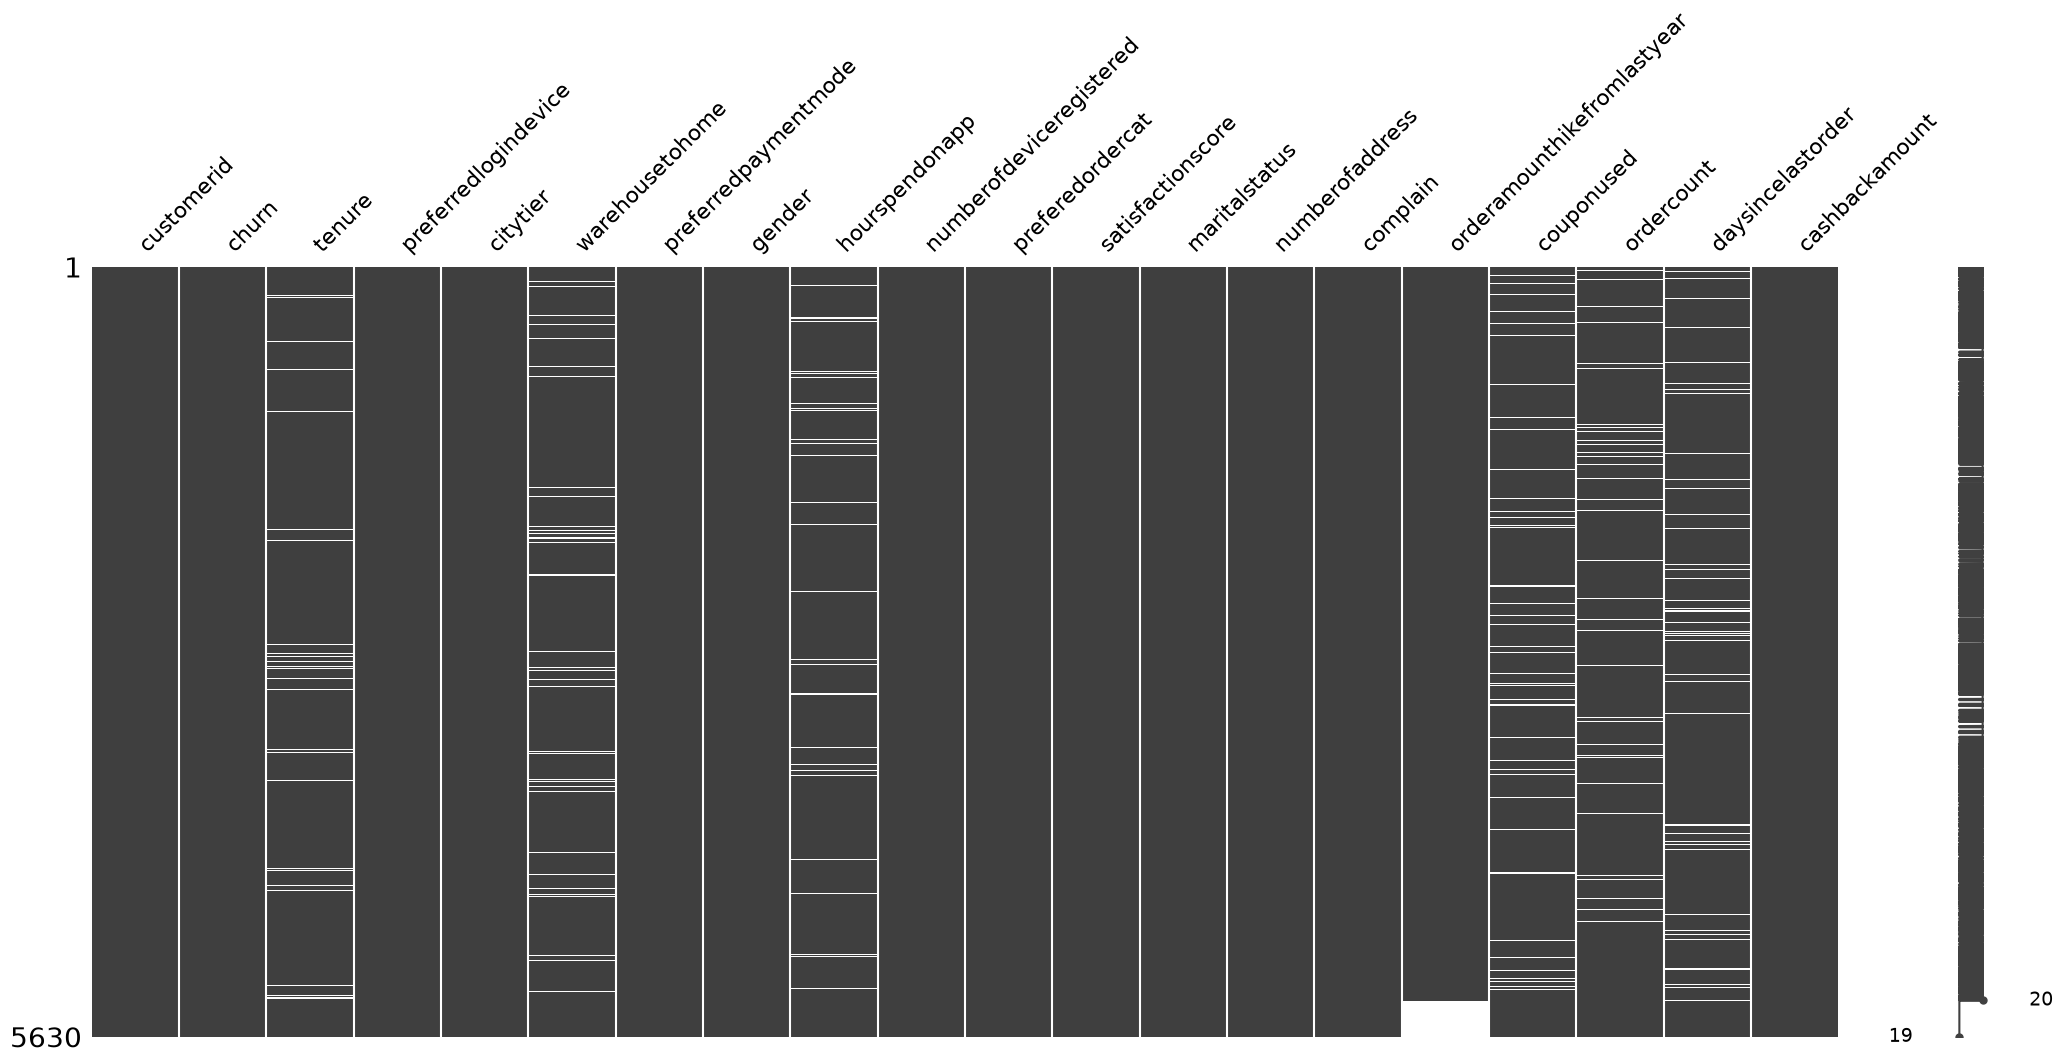

In [8]:
msno.matrix(df)

In [9]:
columns_null = (df.isnull().mean() * 100)[df.isnull().mean() > 0]
columns_null

tenure                         4.689165
warehousetohome                4.458259
hourspendonapp                 4.529307
orderamounthikefromlastyear    4.706927
couponused                     4.547069
ordercount                     4.582593
daysincelastorder              5.452931
dtype: float64

In [10]:
# Lọc ra danh sách các cột có ít nhất một giá trị null
list_null = df.columns[df.isnull().any()].tolist()

df[list_null].dtypes

tenure                         float64
warehousetohome                float64
hourspendonapp                 float64
orderamounthikefromlastyear    float64
couponused                     float64
ordercount                     float64
daysincelastorder              float64
dtype: object

In [11]:
print(df.isna().any(axis=1).mean() * 100)

32.96625222024866


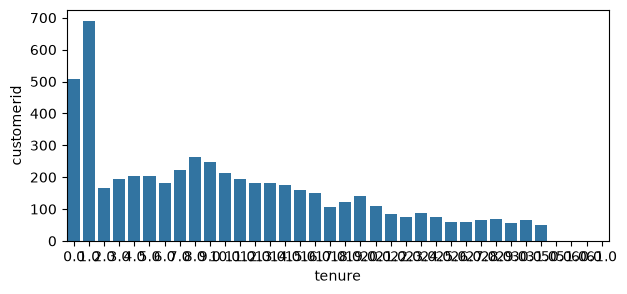

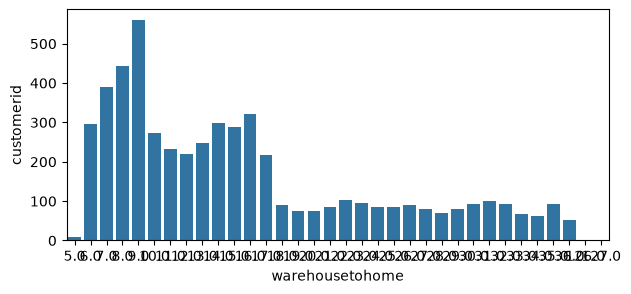

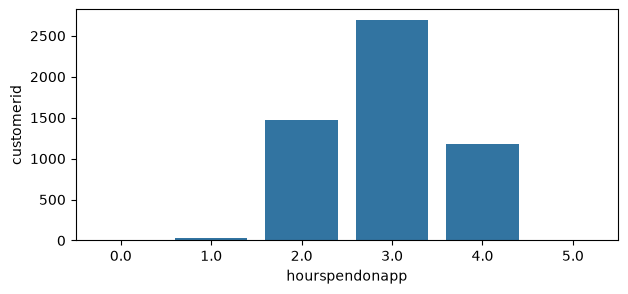

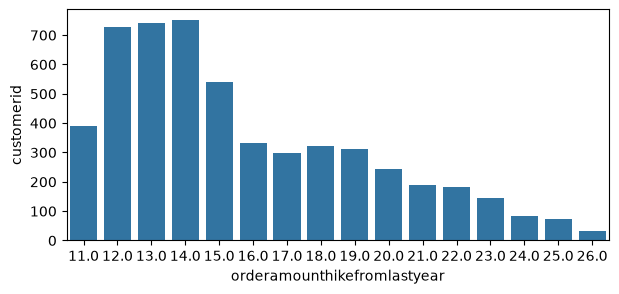

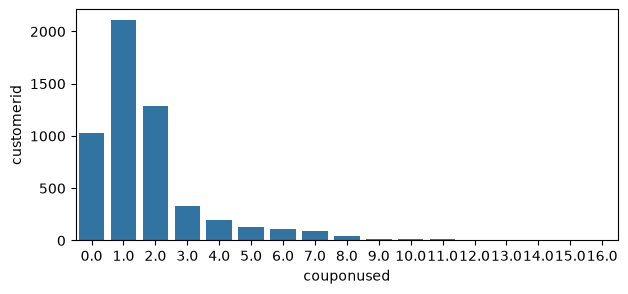

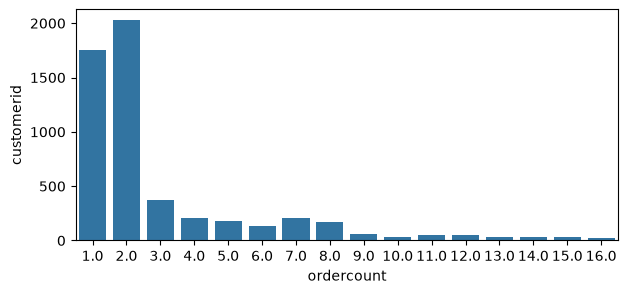

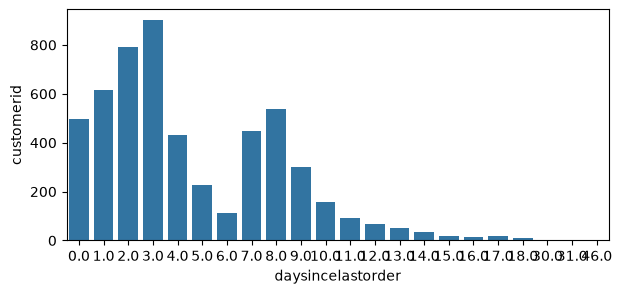

In [12]:
for i in list_null:
    fig, ax = plt.subplots(figsize=(7, 3))
    plot_df = df.groupby(i)[['customerid']].count().reset_index()
    sns.barplot(data = plot_df,x=plot_df[i],y= plot_df['customerid'],ax=ax)
    plt.show()

Sau khi xem xét và dựa trên phân phối của các columns bị missing values có thể thay thế các giá trị thiếu như sau:

        - tenure: median
        - warehousetohome: median
        - hourspendonapp: 0
        - orderamounthikefromlastyear: median
        - couponused: 0
        - ordercount: median
        - daysincelastorder: median

<Axes: >

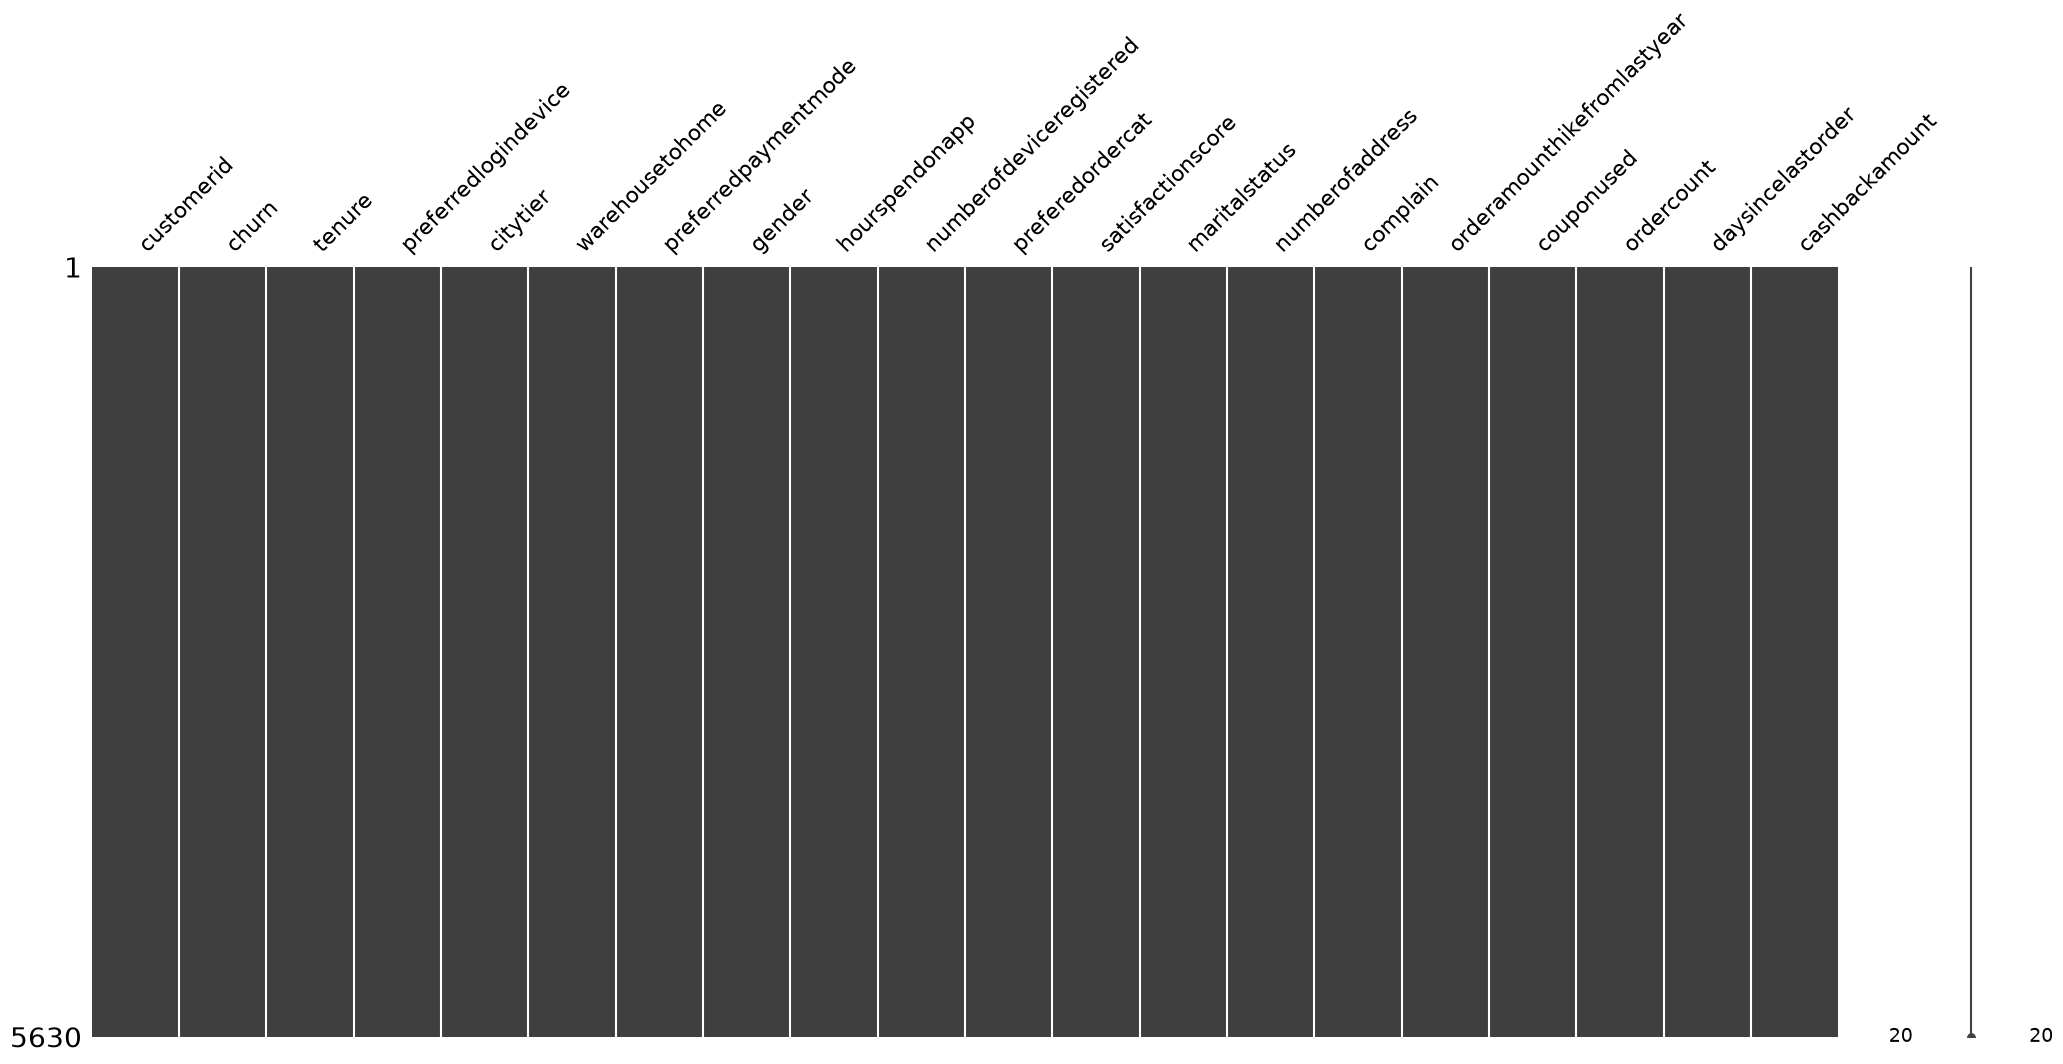

In [13]:
def replace_func(list_column):
  for i in list_column:
    if i in ['tenure', 'warehousetohome', 'orderamounthikefromlastyear', 'ordercount', 'daysincelastorder']:
      df[i] = df[i].fillna(df[i].median())
    else:
      df[i] = df[i].fillna(0)

replace_func(list_null)
msno.matrix(df)

#### **1.2 Duplicated Values:**


In [14]:
df.duplicated().any()

np.False_

#### **1.3 Check same meaning values:**


In [15]:
def check_uniqe():
  for col in df.select_dtypes(exclude='number'):
    print(f"{col}: {df[col].unique()}")

check_uniqe()

preferredlogindevice: <StringArray>
['Mobile Phone', 'Computer', 'Phone']
Length: 3, dtype: str
preferredpaymentmode: <StringArray>
['E wallet', 'Cash on Delivery', 'Debit Card', 'UPI', 'Credit Card', 'COD',
 'CC']
Length: 7, dtype: str
gender: <StringArray>
['Female', 'Male']
Length: 2, dtype: str
preferedordercat: <StringArray>
['Fashion', 'Laptop & Accessory', 'Mobile Phone', 'Grocery', 'Mobile',
 'Others']
Length: 6, dtype: str
maritalstatus: <StringArray>
['Married', 'Single', 'Divorced']
Length: 3, dtype: str


## **Question 1:**
Các hành vi của những người dùng đã rời bỏ là gì? Bạn có đề xuất gì cho công ty để giảm số lượng người dùng rời bỏ?

- Nhóm người dùng mới chiếm tỷ lệ rời bỏ cao &rarr; Đẩy mạnh ưu đãi tân thủ và tối ưu hóa trải nghiệm làm quen sản phẩm (Onboarding).

- Người dùng rời bỏ nhận được ít cashback hơn &rarr; Điều chỉnh tăng tỷ lệ hoàn tiền để tăng tính gắn kết và giá trị nhận được.

- Người dùng rời bỏ có tỷ lệ khiếu nại cao &rarr; Phân tích sâu nội dung khiếu nại để giải quyết triệt để các vấn đề cốt lõi

#### **1.4 EDA by applying Random Forest first:**

In [16]:
# Tạo từ điển để chuẩn hóa
mapping_dict = {
    'preferredlogindevice': {'Phone': 'Mobile Phone'},
    'preferredpaymentmode': {'COD': 'Cash on Delivery', 'CC': 'Credit Card'},
    'preferedordercat': {'Mobile': 'Mobile Phone'}
}

# Áp dụng thay thế
for col, values in mapping_dict.items():
    df[col] = df[col].replace(values)

check_uniqe()

preferredlogindevice: <StringArray>
['Mobile Phone', 'Computer']
Length: 2, dtype: str
preferredpaymentmode: <StringArray>
['E wallet', 'Cash on Delivery', 'Debit Card', 'UPI', 'Credit Card']
Length: 5, dtype: str
gender: <StringArray>
['Female', 'Male']
Length: 2, dtype: str
preferedordercat: <StringArray>
['Fashion', 'Laptop & Accessory', 'Mobile Phone', 'Grocery', 'Others']
Length: 5, dtype: str
maritalstatus: <StringArray>
['Married', 'Single', 'Divorced']
Length: 3, dtype: str


In [17]:
#Encoding:
cate_columns = df.select_dtypes(exclude='number').columns.tolist()
cate_columns

['preferredlogindevice',
 'preferredpaymentmode',
 'gender',
 'preferedordercat',
 'maritalstatus']

In [18]:
encoded_df = pd.get_dummies(df, columns = cate_columns,drop_first=True)
encoded_df.head(5)

,customerid,churn,tenure,citytier,warehousetohome,hourspendonapp,numberofdeviceregistered,satisfactionscore,numberofaddress,complain,...,preferredpaymentmode_Debit Card,preferredpaymentmode_E wallet,preferredpaymentmode_UPI,gender_Male,preferedordercat_Grocery,preferedordercat_Laptop & Accessory,preferedordercat_Mobile Phone,preferedordercat_Others,maritalstatus_Married,maritalstatus_Single
0,52869,0,20.0,3,7.0,4.0,4,5,3,0,...,False,True,False,False,False,False,False,False,True,False
1,52942,0,13.0,1,9.0,4.0,4,3,2,0,...,False,False,False,False,False,False,False,False,False,True
2,52972,0,16.0,3,7.0,3.0,4,3,3,0,...,True,False,False,True,False,True,False,False,False,False
3,53125,0,5.0,1,16.0,3.0,4,4,3,0,...,True,False,False,True,False,False,False,False,True,False
4,53367,0,9.0,1,28.0,3.0,4,2,3,1,...,True,False,False,False,False,True,False,False,False,False


In [19]:
# Bỏ customerid: ID không mang thông tin hành vi, chỉ gây nhiễu cho feature importance
X = encoded_df.drop(['churn', 'customerid'], axis=1)
y = encoded_df['churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = MinMaxScaler()
X_train_scaler = scaler.fit_transform(X_train)
X_test_scaler = scaler.transform(X_test)

In [20]:
clf = RandomForestClassifier(random_state=42)

clf.fit(X_train_scaler, y_train)

y_pred = clf.predict(X_test_scaler)

print(f'Balance accuracy of test set: {balanced_accuracy_score(y_test, y_pred)}')

Balance accuracy of test set: 0.9236054880791723


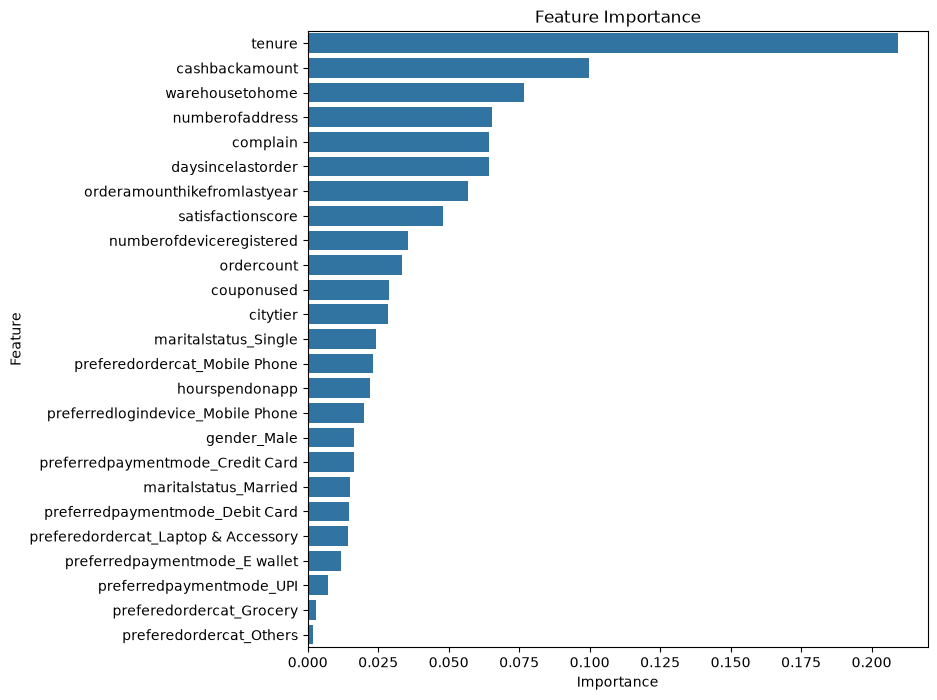

In [21]:
# Feature importance
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': clf.feature_importances_
})

# Sort
feature_importance = feature_importance.sort_values(by='Importance', ascending=False)

# Plot
plt.figure(figsize=(8,8))
sns.barplot(data=feature_importance, x='Importance', y='Feature')
plt.title("Feature Importance")
plt.show()

Như biểu đồ Feature Importance cho thấy, chúng ta có thể thấy các đặc trưng sau có mối liên hệ cao với cột mục tiêu:

* tenure
* cashbackamount
* complain
* warehousetohome
* numberofaddress
* daysincelastorder

&rarr; Chúng ta sẽ phân tích và trực quan hóa các đặc trưng này để có thêm insight.

In [22]:
def count_percentage(df, column, target, count):
    '''
    Tính tỷ lệ churn (target == 1) trên tổng số khách hàng theo từng giá trị của column
    '''

    # Tách 2 nhóm churn / not churn
    churn = df[df[target]==1].groupby(column)[[count]].count().reset_index()
    not_churn = df[df[target]==0].groupby(column)[[count]].count().reset_index()

    # Gộp 2 nhóm
    cate_df = churn.merge(not_churn, on = column , how = 'outer')
    cate_df = cate_df.fillna(0)
    cate_df = cate_df.rename(columns = {count+'_x':'churn',count+'_y':'not_churn'})

    # Tỷ lệ churn
    cate_df['%'] = cate_df['churn']/(cate_df['churn']+cate_df['not_churn'])
    cate_df = cate_df.sort_values(by='%', ascending=False)

    return cate_df

<Axes: xlabel='tenure', ylabel='%'>

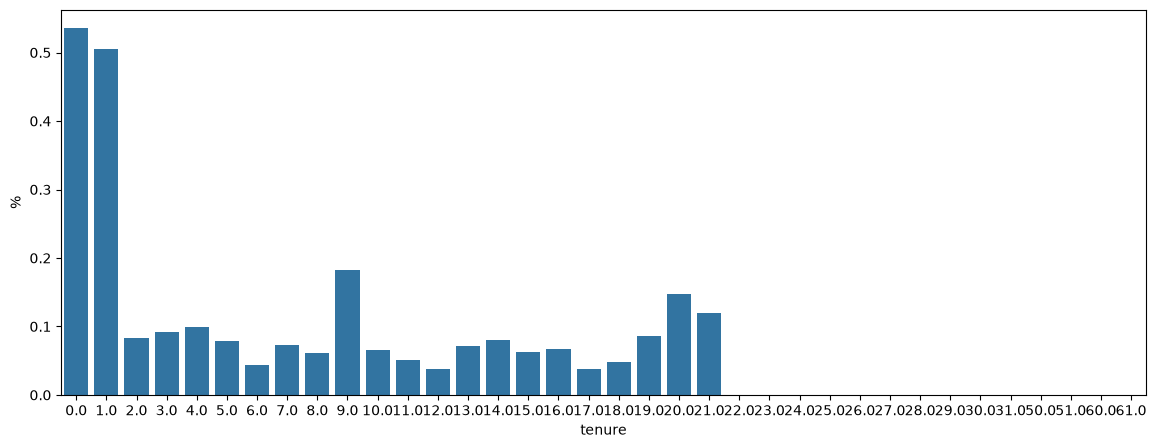

In [23]:
plot_df = count_percentage(df, 'tenure', 'churn', 'customerid')
#Visualize the data:
fig, ax = plt.subplots(figsize=(14, 5))
sns.barplot(data=plot_df, x='tenure',y='%', ax=ax)

<Axes: xlabel='tenure', ylabel='customerid'>

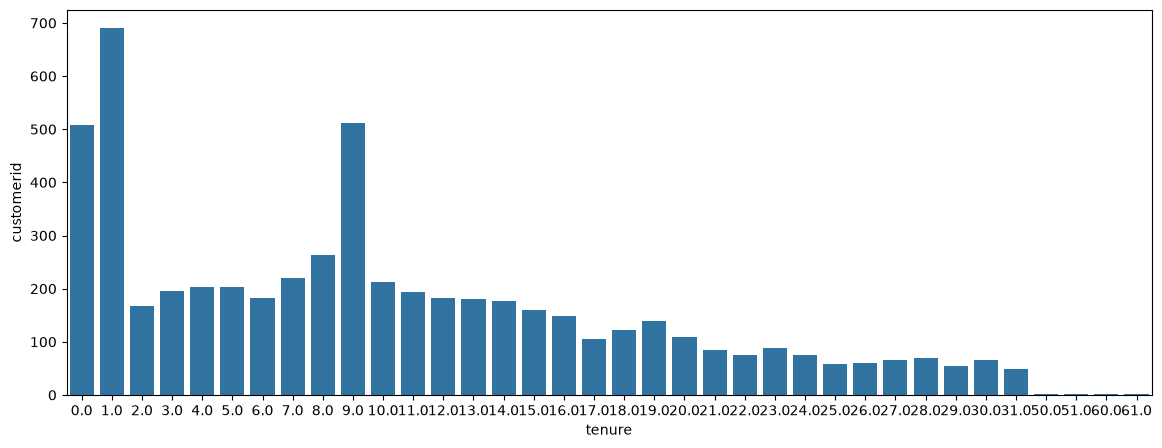

In [24]:
count_df = df.groupby('tenure')[['customerid']].count().reset_index()
#Visualize the data:
fig, ax = plt.subplots(figsize=(14, 5))
sns.barplot(data=count_df, x='tenure',y='customerid', ax=ax)

&rarr; Từ biểu đồ ta thấy người dùng mới có tỷ lệ rời bỏ cao hơn người dùng cũ

<Axes: xlabel='churn', ylabel='warehousetohome'>

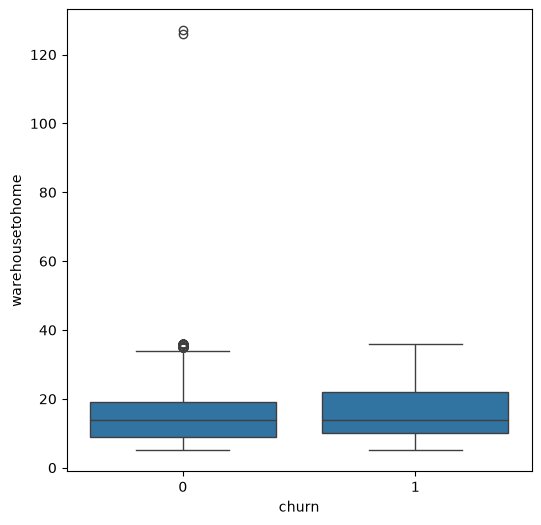

In [25]:
fig, ax = plt.subplots(figsize=(6, 6))
sns.boxplot(data=df, x='churn',y='warehousetohome',ax=ax)

<Axes: xlabel='churn', ylabel='warehousetohome'>

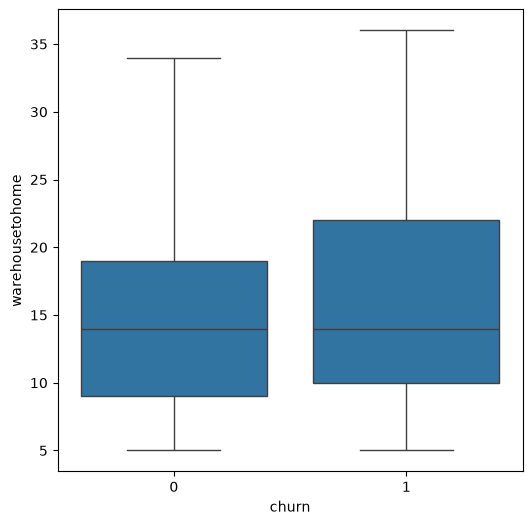

In [26]:
fig, ax = plt.subplots(figsize=(6, 6))
sns.boxplot(data=df, x='churn',y='warehousetohome', ax=ax, showfliers = False)

Đối với cả churn và not churn, phân phối dữ liệu khá tương đồng nhau.

&rarr; Không có bằng chứng rõ ràng cho thấy WarehouseToHome ảnh hưởng đến churn, vì vậy đặc trưng này sẽ được loại khỏi mô hình.

<Axes: xlabel='churn', ylabel='daysincelastorder'>

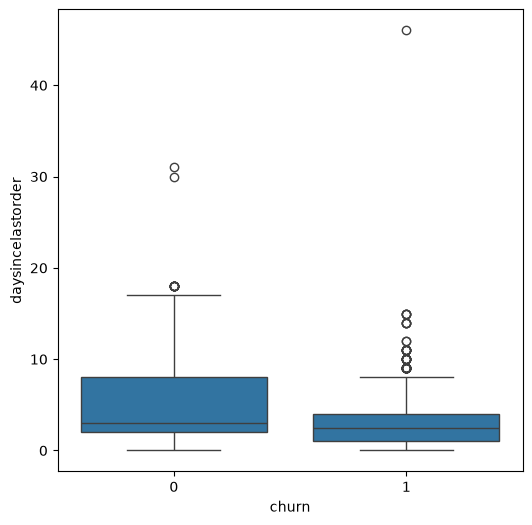

In [27]:
fig, ax = plt.subplots(figsize=(6, 6))
sns.boxplot(data=df, x='churn',y='daysincelastorder',ax=ax)

<Axes: xlabel='churn', ylabel='daysincelastorder'>

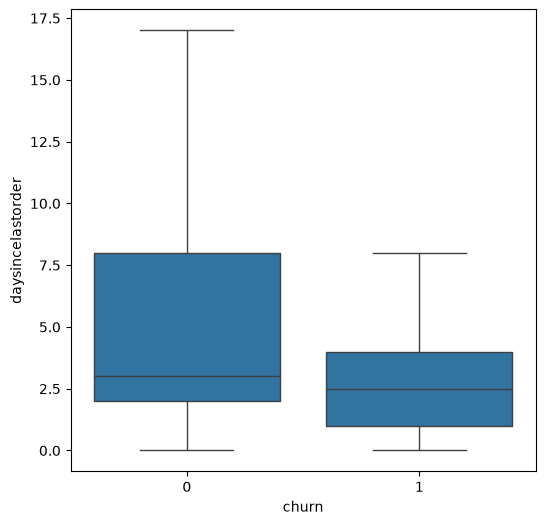

In [28]:
fig, ax = plt.subplots(figsize=(6, 6))
sns.boxplot(data=df, x='churn',y='daysincelastorder',ax=ax, showfliers = False)

Từ biểu đồ, có thể thấy rằng các khách hàng churn đã đặt hàng gần đây hơn (Days Since Last Order thấp hơn so với nhóm không churn).

&rarr; Điều này khá bất thường cần phân tích thêm các đặc trưng khác như SatisfactionScore, Complain,... để tìm hiểu nguyên nhân.

<Axes: xlabel='complain', ylabel='daysincelastorder'>

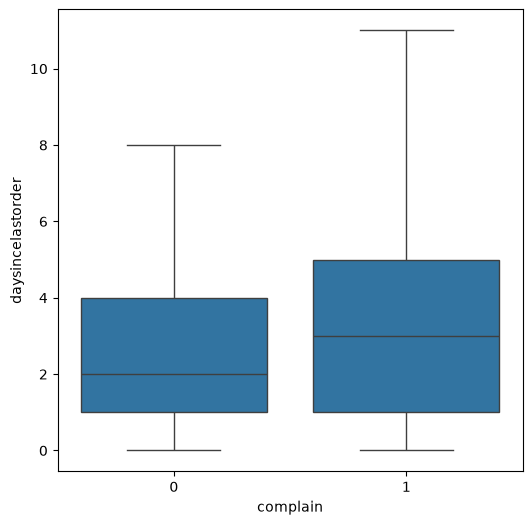

In [29]:
churn_df = df[df['churn']==1]
fig, ax = plt.subplots(figsize=(6, 6))
sns.boxplot(data=churn_df, x='complain',y='daysincelastorder',ax=ax, showfliers = False)

&rarr; Đối với các khách hàng churn có Complain = 1, số ngày kể từ đơn hàng gần nhất (DaysSinceLastOrder) cao hơn so với nhóm churn có Complain = 0.

<Axes: xlabel='churn', ylabel='cashbackamount'>

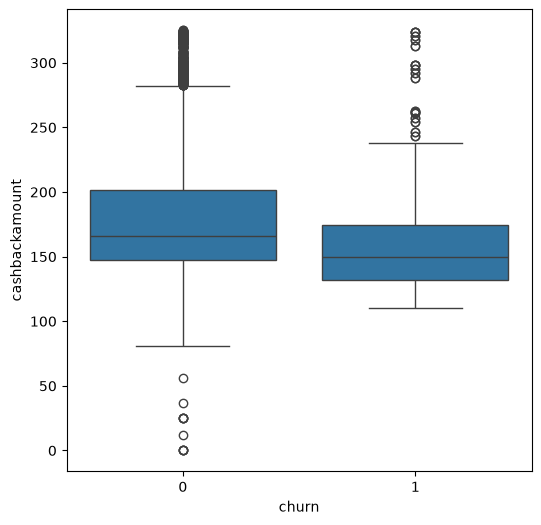

In [30]:
fig, ax = plt.subplots(figsize=(6, 6))
sns.boxplot(data=df, x='churn',y='cashbackamount',ax=ax)

<Axes: xlabel='churn', ylabel='cashbackamount'>

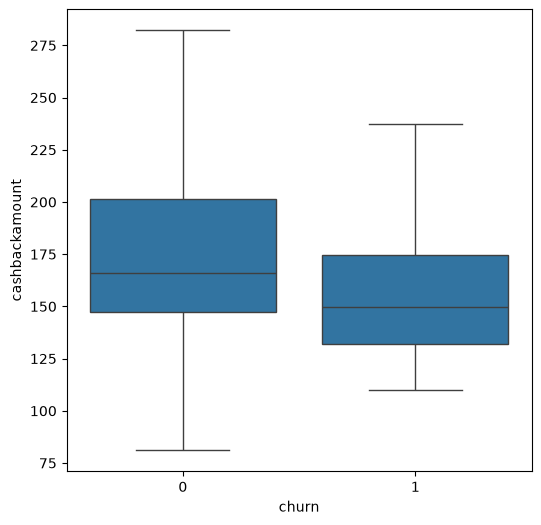

In [31]:
fig, ax = plt.subplots(figsize=(6, 6))
sns.boxplot(data=df, x='churn',y='cashbackamount',ax=ax, showfliers = False)

&rarr; Khách hàng churn nhận được số tiền cashback thấp hơn so với khách hàng không churn.

<Axes: xlabel='churn', ylabel='numberofaddress'>

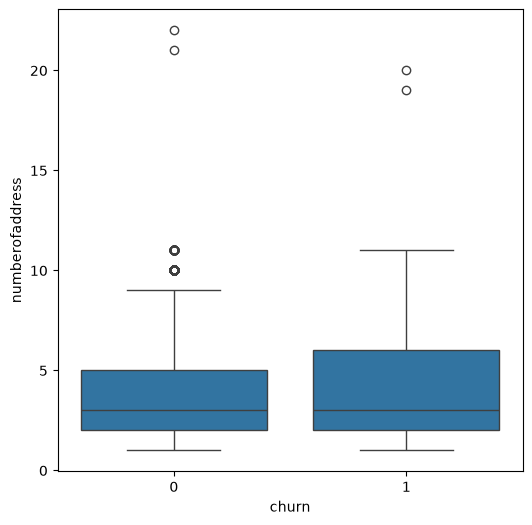

In [32]:
fig, ax = plt.subplots(figsize=(6, 6))
sns.boxplot(data=df, x='churn',y='numberofaddress',ax=ax)

<Axes: xlabel='churn', ylabel='numberofaddress'>

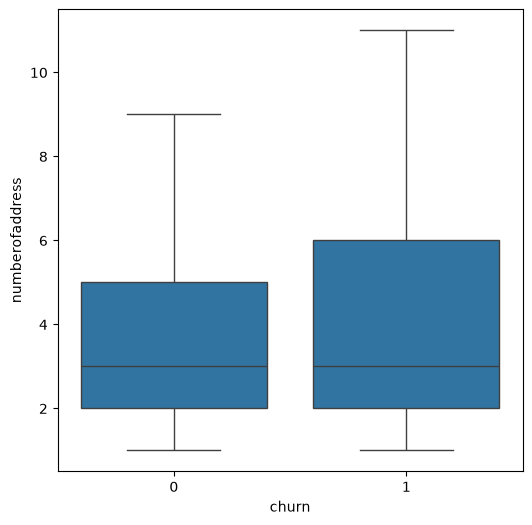

In [33]:
fig, ax = plt.subplots(figsize=(6, 6))
sns.boxplot(data=df, x='churn',y='numberofaddress',ax=ax, showfliers = False)

Nhóm churn (1) có xu hướng có số lượng địa chỉ (NumberOfAddress) cao hơn nhẹ so với nhóm không churn (0).

Median của nhóm churn cao hơn một chút và khoảng phân bố dữ liệu cũng rộng hơn.

Cả hai nhóm có phân phối khá tương đồng, tuy nhiên nhóm không churn xuất hiện nhiều outliers hơn.

&rarr; NumberOfAddress có thể có ảnh hưởng nhẹ đến churn nhưng chưa cho thấy sự khác biệt quá rõ ràng.

<Axes: xlabel='complain', ylabel='%'>

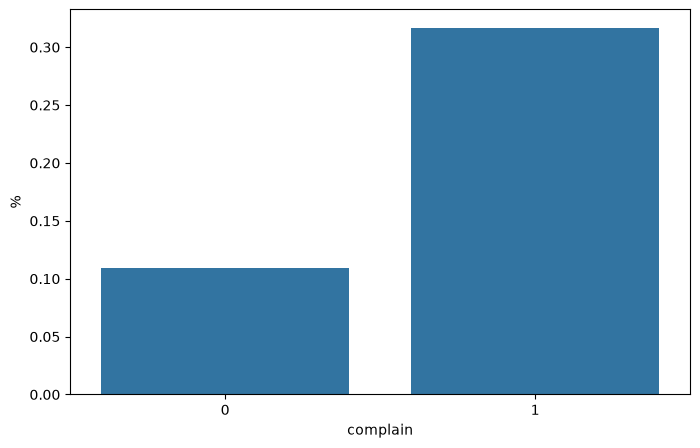

In [34]:
plot_df = count_percentage(df, 'complain', 'churn', 'customerid')
#Visualize the data:
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=plot_df, x='complain',y='%', ax=ax)

&rarr; Tỷ lệ churn ở nhóm khách hàng có khiếu nại (complain = 1) cao hơn rõ rệt so với nhóm không khiếu nại.

#### **1.5 Conclusion & Suggestion**

Khách hàng churn thường là khách hàng mới &rarr; cần tăng ưu đãi và cải thiện trải nghiệm.

Khách hàng churn nhận ít cashback hơn &rarr; nên tăng cashback để giữ chân khách hàng.

Khách hàng churn khiếu nại nhiều hơn &rarr; cần phân tích nguyên nhân và cải thiện dịch vụ.

## **Question 2:**
Xây dựng mô hình Machine Learning để dự đoán người dùng rời bỏ


### **2. Feature Transforming:**

In [35]:
# Bỏ warehousetohome và các khách hàng có numberofaddress bất thường (19-22)
df_model = df.drop(columns = 'warehousetohome')
df_model = df_model.drop(df_model[df_model.numberofaddress.isin([19,20,21,22])].index)
df_model.head(1)

,customerid,churn,tenure,preferredlogindevice,citytier,preferredpaymentmode,gender,hourspendonapp,numberofdeviceregistered,preferedordercat,satisfactionscore,maritalstatus,numberofaddress,complain,orderamounthikefromlastyear,couponused,ordercount,daysincelastorder,cashbackamount
0,52869,0,20.0,Mobile Phone,3,E wallet,Female,4.0,4,Fashion,5,Married,3,0,26.0,5.0,16.0,3.0,229.53


In [36]:
cate_columns = df_model.select_dtypes(exclude='number').columns.tolist()
encoded_df = pd.get_dummies(df_model, columns = cate_columns,drop_first=True)
encoded_df.shape

(5626, 26)

In [37]:
encoded_df.head(3)

,customerid,churn,tenure,citytier,hourspendonapp,numberofdeviceregistered,satisfactionscore,numberofaddress,complain,orderamounthikefromlastyear,...,preferredpaymentmode_Debit Card,preferredpaymentmode_E wallet,preferredpaymentmode_UPI,gender_Male,preferedordercat_Grocery,preferedordercat_Laptop & Accessory,preferedordercat_Mobile Phone,preferedordercat_Others,maritalstatus_Married,maritalstatus_Single
0,52869,0,20.0,3,4.0,4,5,3,0,26.0,...,False,True,False,False,False,False,False,False,True,False
1,52942,0,13.0,1,4.0,4,3,2,0,26.0,...,False,False,False,False,False,False,False,False,False,True
2,52972,0,16.0,3,3.0,4,3,3,0,26.0,...,True,False,False,True,False,True,False,False,False,False


### **3. Model Training & Evaluation**

**3.1 Split train/test set:**

In [38]:
x = encoded_df.drop(['churn','customerid'], axis = 1)
y = encoded_df['churn']

# Train 70% / Validation 15% / Test 15%, giữ nguyên tỷ lệ churn ở mỗi tập
x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.3, random_state=42, stratify=y)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print(f"Training set size: {len(x_train)}")
print(f"Validation set size: {len(x_val)}")
print(f"Test set size: {len(x_test)}")

Training set size: 3938
Validation set size: 844
Test set size: 844


In [39]:
scaler = MinMaxScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_val_scaled=scaler.transform(x_val)
x_test_scaled=scaler.transform(x_test)

**3.2 Choose Base model:**

In [40]:
models = {
    "LogisticRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),
    "DecisionTree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "RandomForest": RandomForestClassifier(n_estimators=200, random_state=42),
    "GradientBoosting": GradientBoostingClassifier(random_state=42),
}

results = []

for name, model in models.items():
    model.fit(x_train, y_train)

    y_pred = model.predict(x_val)

    results.append({
        "model": name,
        "precision": precision_score(y_val, y_pred),
        "recall": recall_score(y_val, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_val, y_pred)
    })

results_df = pd.DataFrame(results).sort_values("balanced_accuracy", ascending=False)
print(results_df)

                model  precision    recall  balanced_accuracy
2        RandomForest   0.951220  0.823944           0.907698
3    GradientBoosting   0.812500  0.640845           0.805465
1        DecisionTree   0.672000  0.591549           0.766572
0  LogisticRegression   0.733945  0.563380           0.761035


**3.3 Enhance Random Forest model**

In [41]:
clf_rand = RandomForestClassifier(random_state=0)

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [20, 30, 40],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False]
}

grid_search = GridSearchCV(clf_rand, param_grid, cv=5, scoring='balanced_accuracy', n_jobs=-1)
grid_search.fit(x_train, y_train)

print("Best Parameters: ", grid_search.best_params_)
print("Best CV balanced accuracy: ", grid_search.best_score_)

Best Parameters:  {'bootstrap': False, 'max_depth': 30, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Best CV balanced accuracy:  0.8866274324268891


**Re-apply model with new parameters:**

In [42]:
best_params = grid_search.best_params_
clf_rand_after = RandomForestClassifier(**best_params, random_state=0)

clf_rand_after.fit(x_train, y_train)
y_ranf_aft_train = clf_rand_after.predict(x_train)
y_ranf_aft_val = clf_rand_after.predict(x_val)

In [43]:
print(f'Balance accuracy of train set: {balanced_accuracy_score(y_train, y_ranf_aft_train)}')
print(f'Balance accuracy of val set: {balanced_accuracy_score(y_val, y_ranf_aft_val)}')

Balance accuracy of train set: 1.0
Balance accuracy of val set: 0.9436218450302958


**&rarr; Balanced accuracy trên tập validation tăng lên ~94% (so với ~91% của Random Forest mặc định) &rarr; sử dụng mô hình này làm mô hình cuối cùng.**

*Lưu ý:* balanced accuracy trên tập train = 1.0 cho thấy mô hình có dấu hiệu overfitting (cây sâu, `bootstrap=False`). Có thể giảm bằng cách giới hạn `max_depth`, tăng `min_samples_leaf` hoặc dùng `class_weight='balanced'`.

Balance accuracy of test set: 0.9245917098029774
              precision    recall  f1-score   support

   Not churn       0.97      0.99      0.98       702
       Churn       0.95      0.86      0.90       142

    accuracy                           0.97       844
   macro avg       0.96      0.92      0.94       844
weighted avg       0.97      0.97      0.97       844



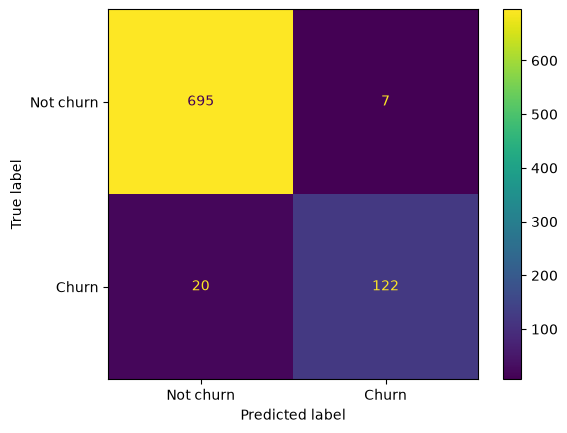

In [44]:
y_pred_test = clf_rand_after.predict(x_test)
print(f'Balance accuracy of test set: {balanced_accuracy_score(y_test, y_pred_test)}')
print(classification_report(y_test, y_pred_test, target_names=['Not churn', 'Churn']))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, display_labels=['Not churn', 'Churn'])
plt.show()

&rarr; **Trên tập test, balanced accuracy đạt ~92%, recall của lớp churn ~0.86 (bắt được 86% khách hàng sẽ rời bỏ) với precision ~0.95 &rarr; mô hình hoạt động tốt.**

## **Question 3:**
Dựa trên hành vi của những người dùng rời bỏ, công ty muốn đưa ra một số khuyến mãi đặc biệt cho họ


### **1. Get the data prepared**

Thu thập tất cả các đặc điểm của người dùng đã rời bỏ để phân cụm

In [45]:
# Prepare data:
df_churned = df[df['churn']==1].drop(columns = ['customerid','churn'])
print(df_churned.shape)
df_churned.head(5)

(948, 18)


,tenure,preferredlogindevice,citytier,warehousetohome,preferredpaymentmode,gender,hourspendonapp,numberofdeviceregistered,preferedordercat,satisfactionscore,maritalstatus,numberofaddress,complain,orderamounthikefromlastyear,couponused,ordercount,daysincelastorder,cashbackamount
7,1.0,Computer,1,17.0,Credit Card,Female,4.0,5,Mobile Phone,4,Single,3,1,26.0,2.0,2.0,1.0,143.59
24,1.0,Computer,1,17.0,Credit Card,Female,4.0,5,Mobile Phone,4,Single,3,1,26.0,1.0,2.0,1.0,143.59
40,9.0,Computer,1,16.0,Credit Card,Female,3.0,4,Mobile Phone,4,Single,2,1,25.0,1.0,1.0,0.0,118.59
58,9.0,Computer,1,16.0,Credit Card,Female,3.0,4,Mobile Phone,4,Single,2,1,25.0,0.0,1.0,0.0,118.59
68,1.0,Computer,1,14.0,Debit Card,Male,4.0,6,Laptop & Accessory,3,Single,3,1,25.0,2.0,2.0,7.0,185.74


In [46]:
# Transform data:
cate_columns = df_churned.select_dtypes(exclude='number').columns.tolist()
encoded_df = pd.get_dummies(df_churned, columns = cate_columns, drop_first=True)

# Normalization:
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(encoded_df)
scaled_df = pd.DataFrame(scaled_data, columns = encoded_df.columns.tolist())

In [47]:
scaled_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 948 entries, 0 to 947
Data columns (total 25 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   tenure                               948 non-null    float64
 1   citytier                             948 non-null    float64
 2   warehousetohome                      948 non-null    float64
 3   hourspendonapp                       948 non-null    float64
 4   numberofdeviceregistered             948 non-null    float64
 5   satisfactionscore                    948 non-null    float64
 6   numberofaddress                      948 non-null    float64
 7   complain                             948 non-null    float64
 8   orderamounthikefromlastyear          948 non-null    float64
 9   couponused                           948 non-null    float64
 10  ordercount                           948 non-null    float64
 11  daysincelastorder                    948 no

In [48]:
pca = PCA(n_components=3)
pca.fit(scaled_df)
PCA_df = pd.DataFrame(pca.transform(scaled_df), columns=['PC1', 'PC2', 'PC3'])
PCA_df.head()

,PC1,PC2,PC3
0,0.811777,0.217969,-0.567602
1,0.812928,0.218102,-0.568461
2,0.829154,0.205540,-0.551977
3,0.830305,0.205673,-0.552836
4,-0.023262,0.808650,0.476491


In [49]:
pca.explained_variance_ratio_

array([0.15476489, 0.15011096, 0.10527747])

### **2. Apply KMeans model**

2.1. Choosing K:

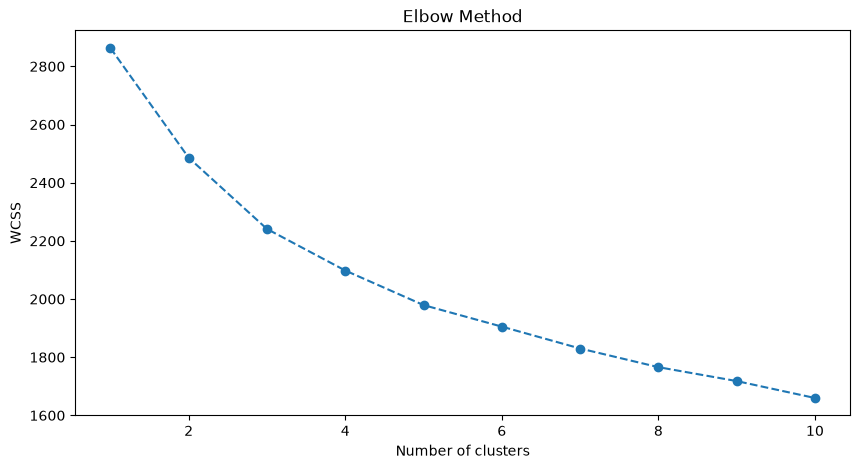

In [50]:
ss = []
max_clusters = 10
for i in range(1, max_clusters+1):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(scaled_df)
    # Inertia method returns WCSS for that model
    ss.append(kmeans.inertia_)

# Plot the Elbow method
plt.figure(figsize=(10,5))
plt.plot(range(1, max_clusters+1), ss, marker='o', linestyle='--')
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

PCA chỉ giải thích được một phần nhỏ phương sai dữ liệu và Elbow Method không cho thấy điểm khuỷu tay rõ ràng.

→ Dùng thêm Silhouette Score để chọn K.

In [51]:
sil = {}
for k in range(2, 9):
    labels = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10).fit_predict(scaled_df)
    sil[k] = silhouette_score(scaled_df, labels)

pd.Series(sil, name='silhouette_score')

2    0.131201
3    0.132872
4    0.136019
5    0.123678
6    0.126191
7    0.128277
8    0.136798
Name: silhouette_score, dtype: float64

**2.2. Apply KMeans với K đã chọn**

In [52]:
k = 4
kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
df_churned['cluster'] = kmeans.fit_predict(scaled_df)

df_churned['cluster'].value_counts().sort_index()

cluster
0    192
1    346
2    244
3    166
Name: count, dtype: int64

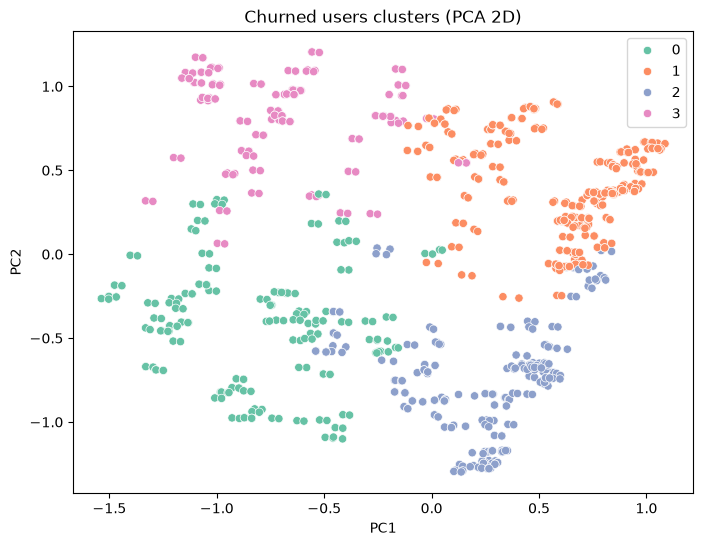

In [53]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=PCA_df['PC1'], y=PCA_df['PC2'], hue=df_churned['cluster'].values, palette='Set2', ax=ax)
ax.set_title('Churned users clusters (PCA 2D)')
plt.show()

### **3. Cluster profiling**

In [54]:
num_cols = df_churned.select_dtypes(include='number').columns.drop('cluster')
df_churned.groupby('cluster')[num_cols].mean().T.round(2)

cluster,0,1,2,3
tenure,5.28,2.71,3.85,4.62
citytier,2.06,1.53,1.45,2.73
warehousetohome,18.92,15.42,15.79,19.03
hourspendonapp,2.95,2.71,2.66,2.92
numberofdeviceregistered,3.98,3.95,3.93,3.87
satisfactionscore,3.20,3.45,3.35,3.54
numberofaddress,5.23,3.61,4.56,5.23
complain,0.34,0.49,0.69,0.64
orderamounthikefromlastyear,14.68,15.88,15.44,16.43
couponused,2.31,1.41,1.46,1.98


In [55]:
df_churned.groupby('cluster')[cate_columns].agg(lambda s: s.mode().iloc[0]).T

cluster,0,1,2,3
preferredlogindevice,Mobile Phone,Mobile Phone,Mobile Phone,Mobile Phone
preferredpaymentmode,Credit Card,Debit Card,Debit Card,Debit Card
gender,Male,Male,Male,Male
preferedordercat,Laptop & Accessory,Mobile Phone,Mobile Phone,Laptop & Accessory
maritalstatus,Married,Single,Married,Single


Silhouette Score của mọi K đều thấp (~0.12-0.14) → các cụm không tách biệt rõ, nên kết quả phân cụm chỉ mang tính tham khảo. Chọn **K = 4** vì có silhouette cao nhất trong các K nhỏ, đủ ít nhóm để triển khai khuyến mãi.

| Cụm | Đặc điểm nổi bật | Đề xuất khuyến mãi |
|---|---|---|
| **0** (~192 KH) – *Khách lâu năm, giá trị cao* | Tenure cao nhất, nhiều đơn hàng, dùng nhiều coupon, cashback cao nhất, ít khiếu nại nhất, nhưng điểm hài lòng thấp nhất; chủ yếu đã kết hôn, mua Laptop & Accessory, trả bằng Credit Card | Chương trình khách hàng thân thiết / hạng thành viên, ưu đãi riêng cho Laptop & Accessory, khảo sát để cải thiện mức hài lòng |
| **1** (~346 KH) – *Khách mới, ít tương tác* | Tenure thấp nhất, ít đơn, cashback thấp, độc thân, mua Mobile Phone, City tier 1 | Ưu đãi onboarding, voucher cho đơn hàng thứ 2-3, tăng cashback cho điện thoại |
| **2** (~244 KH) – *Khách mới hay khiếu nại* | Tỷ lệ khiếu nại cao nhất (~69%), tenure thấp, ít đơn, cashback thấp, đã kết hôn, mua Mobile Phone | Chủ động liên hệ xử lý khiếu nại, voucher xin lỗi/bồi thường, cải thiện chất lượng dịch vụ |
| **3** (~166 KH) – *Khách ở tỉnh xa* | City tier 3, xa kho nhất, khiếu nại cao (~64%), cashback khá cao, điểm hài lòng cao nhất, độc thân, mua Laptop & Accessory | Miễn phí / giảm phí vận chuyển, cải thiện tốc độ giao hàng cho vùng xa |